## Data Visualization with Seaborn


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")

sales = pd.read_csv(r"A:\Developers Arena\week6\sales_data.csv")
sales["Date"] = pd.to_datetime(sales["Date"])

sales.head()

,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


In [21]:
print("Shape:", sales.shape)
print("\nColumns and types:")
sales.info()

print("\nMissing values:")
print(sales.isna().sum())

# Remove rows missing values required for analysis
sales = sales.dropna(
    subset=["Date", "Product", "Quantity", "Price", "Region", "Total_Sales"]
).copy()

# Ensure numeric columns are numeric
for column in ["Quantity", "Price", "Total_Sales"]:
    sales[column] = pd.to_numeric(sales[column], errors="coerce")

sales = sales.dropna(subset=["Quantity", "Price", "Total_Sales"])

print("\nRows after cleaning:", len(sales))

Shape: (100, 7)

Columns and types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         100 non-null    datetime64[ns]
 1   Product      100 non-null    object        
 2   Quantity     100 non-null    int64         
 3   Price        100 non-null    int64         
 4   Customer_ID  100 non-null    object        
 5   Region       100 non-null    object        
 6   Total_Sales  100 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 5.6+ KB

Missing values:
Date           0
Product        0
Quantity       0
Price          0
Customer_ID    0
Region         0
Total_Sales    0
dtype: int64

Rows after cleaning: 100


In [22]:
daily_sales = (
    sales.groupby("Date", as_index=False)["Total_Sales"]
    .sum()
)

product_sales = (
    sales.groupby("Product", as_index=False)["Total_Sales"]
    .sum()
    .sort_values("Total_Sales", ascending=False)
)

region_sales = (
    sales.groupby("Region", as_index=False)["Total_Sales"]
    .sum()
    .sort_values("Total_Sales", ascending=False)
)

product_region_sales = sales.pivot_table(
    index="Product",
    columns="Region",
    values="Total_Sales",
    aggfunc="sum",
    fill_value=0,
)

product_sales

,Product,Total_Sales
1,Laptop,3889210
4,Tablet,2884340
3,Phone,2859394
0,Headphones,1384033
2,Monitor,1348071


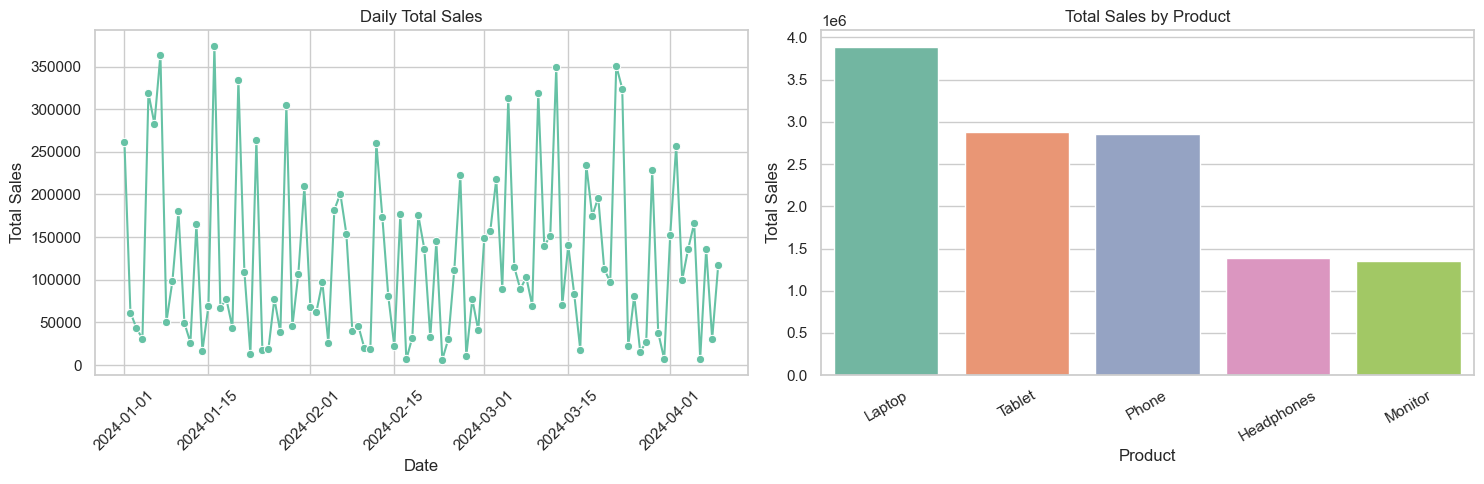

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=daily_sales,
    x="Date",
    y="Total_Sales",
    marker="o",
    ax=axes[0],
)
axes[0].set_title("Daily Total Sales")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Total Sales")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(
    data=product_sales,
    x="Product",
    y="Total_Sales",
    hue="Product",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Total Sales by Product")
axes[1].set_xlabel("Product")
axes[1].set_ylabel("Total Sales")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

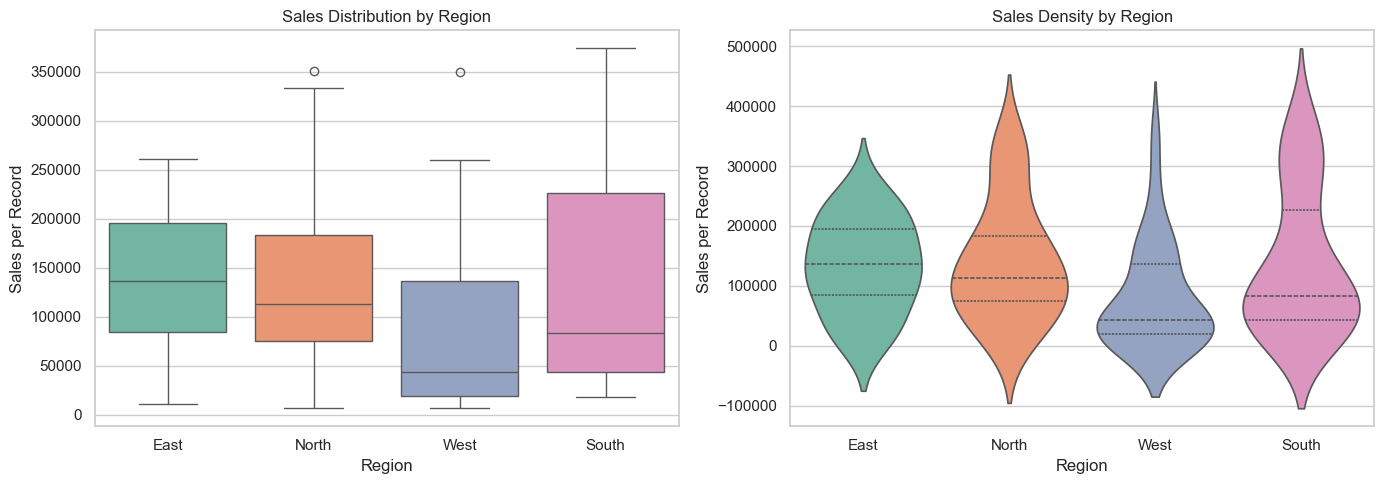

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=sales,
    x="Region",
    y="Total_Sales",
    hue="Region",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Sales Distribution by Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Sales per Record")

sns.violinplot(
    data=sales,
    x="Region",
    y="Total_Sales",
    hue="Region",
    legend=False,
    inner="quart",
    ax=axes[1],
)
axes[1].set_title("Sales Density by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Sales per Record")

plt.tight_layout()
plt.show()

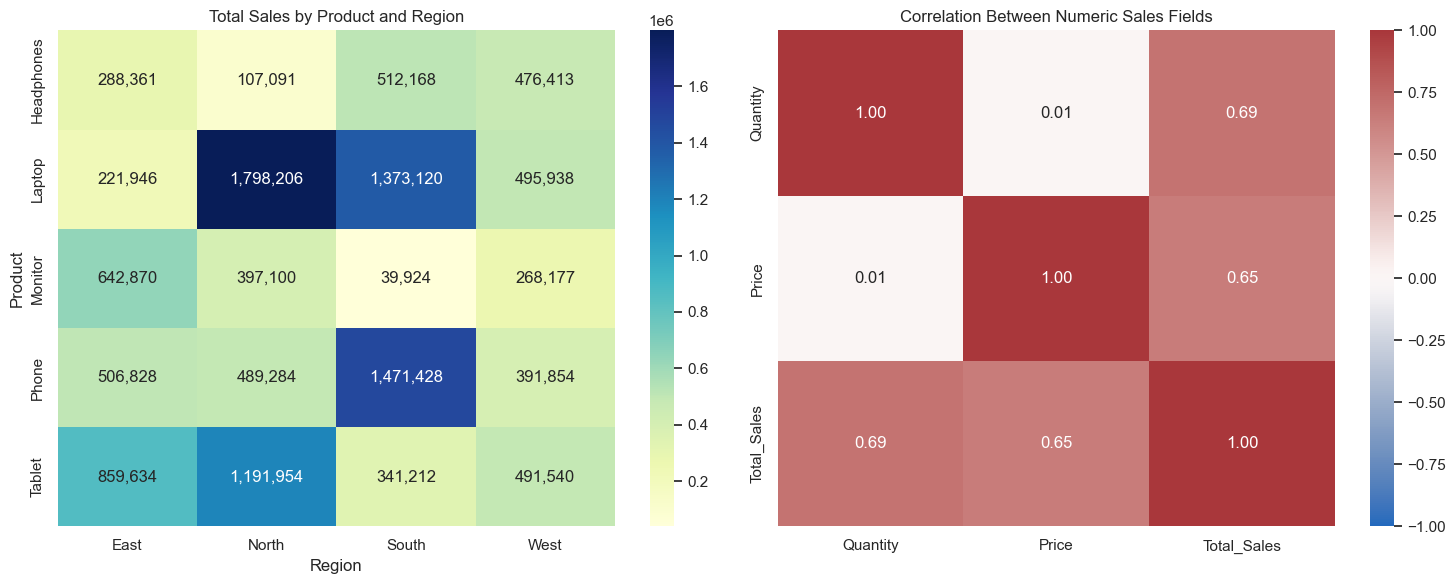

In [25]:
numeric_columns = ["Quantity", "Price", "Total_Sales"]
correlations = sales[numeric_columns].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    product_region_sales,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    ax=axes[0],
)
axes[0].set_title("Total Sales by Product and Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Product")

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("Correlation Between Numeric Sales Fields")

plt.tight_layout()
plt.show()

In [26]:
import plotly.express as px

fig = px.scatter(
    sales,
    x="Quantity",
    y="Total_Sales",
    color="Product",
    size="Price",
    hover_data=["Date", "Region", "Customer_ID"],
    title="Interactive Sales: Quantity vs. Total Sales",
    labels={
        "Quantity": "Quantity Sold",
        "Total_Sales": "Total Sales",
        "Price": "Unit Price",
    },
    template="plotly_white",
)

fig.show()

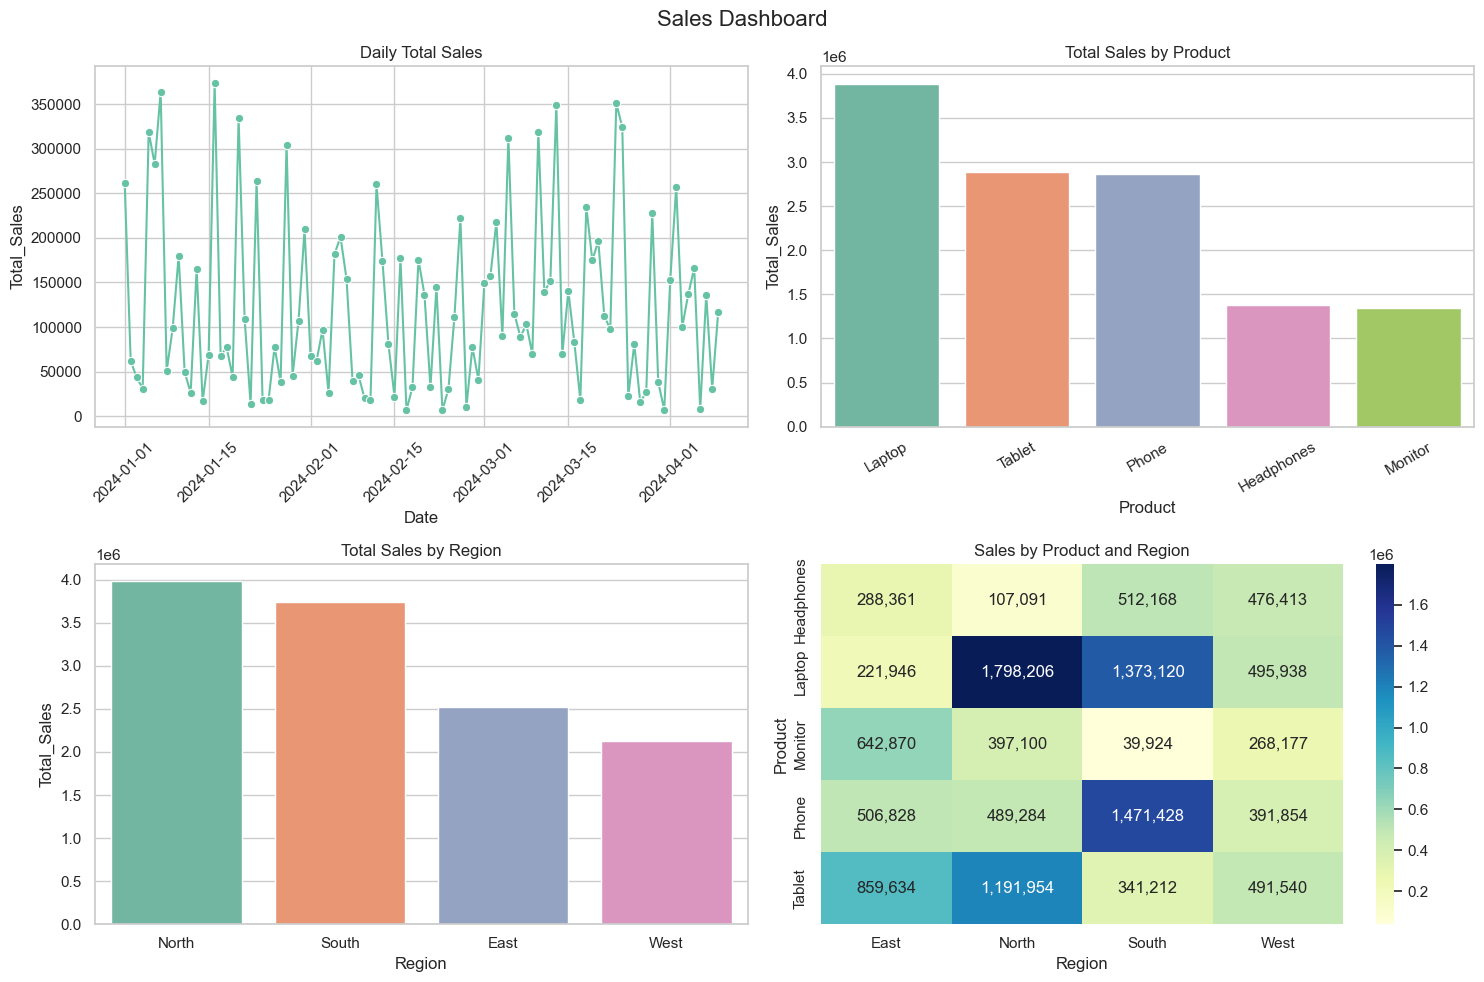

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.lineplot(
    data=daily_sales,
    x="Date",
    y="Total_Sales",
    marker="o",
    ax=axes[0, 0],
)
axes[0, 0].set_title("Daily Total Sales")
axes[0, 0].tick_params(axis="x", rotation=45)

sns.barplot(
    data=product_sales,
    x="Product",
    y="Total_Sales",
    hue="Product",
    palette="Set2",
    legend=False,
    ax=axes[0, 1],
)
axes[0, 1].set_title("Total Sales by Product")
axes[0, 1].tick_params(axis="x", rotation=30)

sns.barplot(
    data=region_sales,
    x="Region",
    y="Total_Sales",
    hue="Region",
    palette="Set2",
    legend=False,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Total Sales by Region")

sns.heatmap(
    product_region_sales,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    ax=axes[1, 1],
)
axes[1, 1].set_title("Sales by Product and Region")

fig.suptitle("Sales Dashboard", fontsize=16)
fig.tight_layout()
plt.show()